### Ans 3. Import libraries and generate the dataset

Feature matrix shape: (200, 2)
Label vector shape: (200,)
Class distribution: {np.int64(0): 100, np.int64(1): 100}


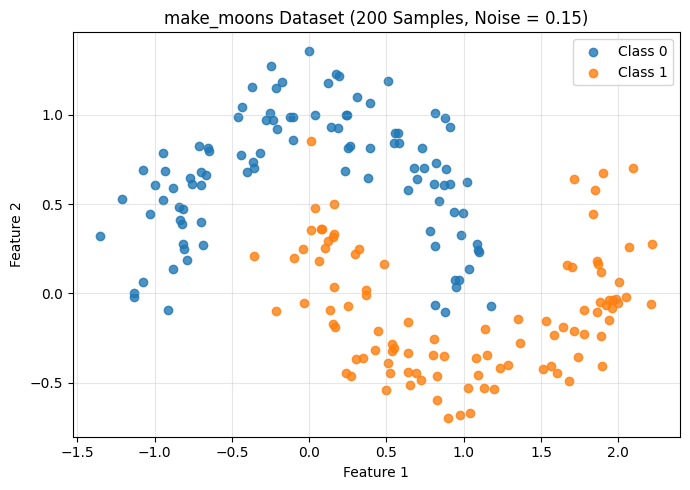

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons

# Generate the exact dataset specified in HW3
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Class distribution:", dict(Counter(y)))

# Visualize the generated dataset
plt.figure(figsize=(7, 5))

for label in np.unique(y):
    plt.scatter(
        X[y == label, 0],
        X[y == label, 1],
        label=f"Class {label}",
        alpha=0.8
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("make_moons Dataset (200 Samples, Noise = 0.15)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Implement distance function and custom k-NN

In [2]:

def lp_distance(v1, v2, p):
    """Compute the Minkowski Lp distance between two vectors."""
    v1 = np.asarray(v1, dtype=float)
    v2 = np.asarray(v2, dtype=float)

    if p < 1:
        raise ValueError("p must be at least 1")
    if v1.shape != v2.shape:
        raise ValueError("Vectors must have equal dimensions")

    return float(np.sum(np.abs(v1 - v2) ** p) ** (1 / p))


def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
    """
    Predict one test record using a custom exact k-NN classifier.

    y_test is accepted for interface compatibility but is not used
    to predict the class.
    """
    N = len(X_train)

    if not 1 <= k <= N:
        raise ValueError("k must be between 1 and N")

    distances = []

    # Calculate distance from test point to each training record
    for i in range(N):
        distance = distance_func(X_train[i], X_test)
        distances.append((distance, y_train[i]))

    # Select the exact k nearest neighbors
    distances.sort(key=lambda item: item[0])
    neighbors = distances[:k]

    # Count votes for each class
    votes = Counter(label for distance, label in neighbors)
    max_votes = max(votes.values())

    tied_classes = [
        label for label, count in votes.items()
        if count == max_votes
    ]

    if len(tied_classes) == 1:
        predicted_class = tied_classes[0]
    else:
        # Resolve vote ties using total neighbor distance
        total_distance = {
            label: sum(
                distance for distance, neighbor_label in neighbors
                if neighbor_label == label
            )
            for label in tied_classes
        }

        predicted_class = min(
            tied_classes,
            key=lambda label: (total_distance[label], label)
        )

    return int(predicted_class)


# Distance metrics
distance_metrics = {
    "Euclidean": lambda v1, v2: lp_distance(v1, v2, 2),
    "Manhattan": lambda v1, v2: lp_distance(v1, v2, 1)
}


### Compute all 18 predictions and vote counts

In [3]:

test_points = [
    (0.40, 0.45),
    (0.08, 0.78),
    (0.75, -0.15)
]

k_values = [1, 3, 5]
results = []

for point in test_points:
    for metric_name, distance_func in distance_metrics.items():
        for k in k_values:

            # Compute and sort all distances
            distances = [
                (distance_func(X[i], point), int(y[i]))
                for i in range(len(X))
            ]
            distances.sort(key=lambda item: item[0])

            neighbors = distances[:k]
            votes = Counter(label for distance, label in neighbors)

            # Predict using our custom k-NN implementation
            prediction = knn_predict(
                X, y, np.array(point), None, k, distance_func
            )

            results.append({
                "Test Point": str(point),
                "Distance Metric": metric_name,
                "k": k,
                "Class 0 Votes": votes.get(0, 0),
                "Class 1 Votes": votes.get(1, 0),
                "Predicted Class": prediction
            })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

# Verify that every required combination is included
assert len(results_df) == 18

# Verify that vote counts sum to k
assert all(
    results_df["Class 0 Votes"] +
    results_df["Class 1 Votes"] == results_df["k"]
)


   Test Point Distance Metric  k  Class 0 Votes  Class 1 Votes  Predicted Class
  (0.4, 0.45)       Euclidean  1              1              0                0
  (0.4, 0.45)       Euclidean  3              1              2                1
  (0.4, 0.45)       Euclidean  5              1              4                1
  (0.4, 0.45)       Manhattan  1              1              0                0
  (0.4, 0.45)       Manhattan  3              1              2                1
  (0.4, 0.45)       Manhattan  5              1              4                1
 (0.08, 0.78)       Euclidean  1              0              1                1
 (0.08, 0.78)       Euclidean  3              2              1                0
 (0.08, 0.78)       Euclidean  5              4              1                0
 (0.08, 0.78)       Manhattan  1              0              1                1
 (0.08, 0.78)       Manhattan  3              2              1                0
 (0.08, 0.78)       Manhattan  5        

### Verify the minimal example in Python

In [4]:

# Minimal constructed example for Q3(d)
X_min = np.array([
    [1.0, 0.0],  # Class 0
    [0.6, 0.6]   # Class 1
])

y_min = np.array([0, 1])
test_min = np.array([0.0, 0.0])

for metric_name, distance_func in distance_metrics.items():
    distances = [
        distance_func(record, test_min)
        for record in X_min
    ]

    prediction = knn_predict(
        X_min, y_min, test_min, None, 1, distance_func
    )

    print(f"{metric_name}:")
    print(f"  Distance to Class 0: {distances[0]:.4f}")
    print(f"  Distance to Class 1: {distances[1]:.4f}")
    print(f"  Predicted class: {prediction}")


Euclidean:
  Distance to Class 0: 1.0000
  Distance to Class 1: 0.8485
  Predicted class: 1
Manhattan:
  Distance to Class 0: 1.0000
  Distance to Class 1: 1.2000
  Predicted class: 0


### Ans 4 - k-NN Decision Boundaries and Bias–Variance Comparison

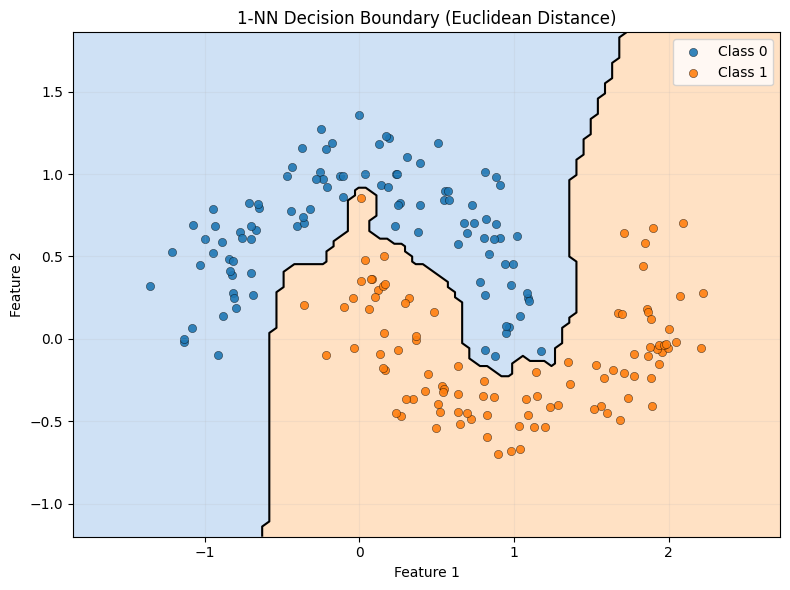

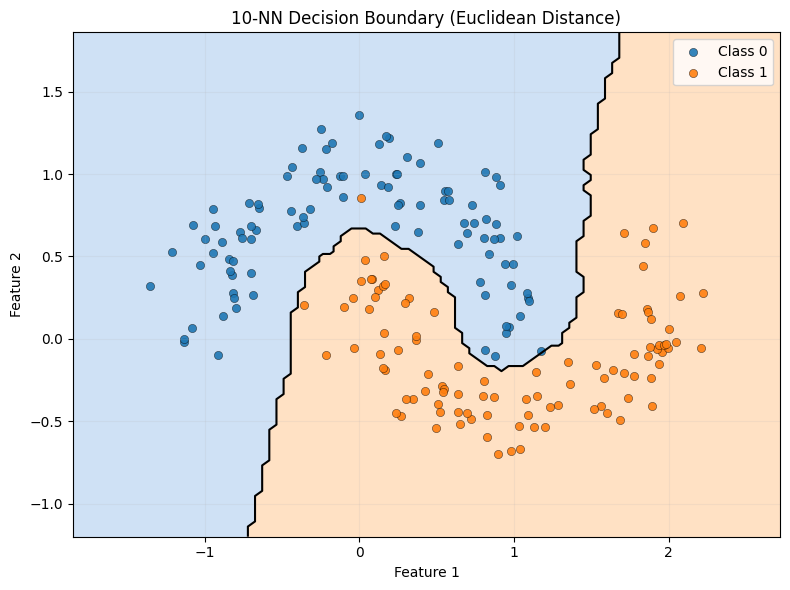

In [5]:

# ============================================================
# CS6220 HW3 - Answer 4
# Decision Boundary Visualization: 1-NN vs 10-NN
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def visualize_knn(X_train, y_train, k, distance_func,
                  grid_resolution=100):
    """
    Visualize the decision boundary of a custom k-NN classifier.

    Parameters
    ----------
    X_train : numpy.ndarray
        Training features with shape (N, 2).
    y_train : numpy.ndarray
        Binary training labels (0 or 1).
    k : int
        Number of nearest neighbors.
    distance_func : callable
        Distance function between two feature vectors.
    grid_resolution : int
        Number of grid points along each axis.
    """

    X_train = np.asarray(X_train)
    y_train = np.asarray(y_train)

    if X_train.ndim != 2 or X_train.shape[1] != 2:
        raise ValueError("X_train must have exactly 2 features.")

    if not np.all(np.isin(y_train, [0, 1])):
        raise ValueError("Only binary labels 0 and 1 are supported.")

    # Define plot limits with padding
    x_min = X_train[:, 0].min() - 0.5
    x_max = X_train[:, 0].max() + 0.5
    y_min = X_train[:, 1].min() - 0.5
    y_max = X_train[:, 1].max() + 0.5

    # Generate a regular 100 x 100 grid
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_resolution),
        np.linspace(y_min, y_max, grid_resolution)
    )

    grid_points = np.column_stack((xx.ravel(), yy.ravel()))

    # Predict each grid point using our custom k-NN
    predictions = np.array([
        knn_predict(
            X_train,
            y_train,
            point,
            None,
            k,
            distance_func
        )
        for point in grid_points
    ])

    Z = predictions.reshape(xx.shape)

    # Define background and training-point colors
    background_cmap = ListedColormap(["#BFD7F2", "#FFD7B0"])
    point_colors = ["#1F77B4", "#FF7F0E"]

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot predicted classification regions
    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        cmap=background_cmap,
        alpha=0.75
    )

    # Draw the decision boundary
    if np.unique(Z).size > 1:
        ax.contour(
            xx, yy, Z,
            levels=[0.5],
            colors="black",
            linewidths=1.5
        )

    # Overlay actual training records
    for label in [0, 1]:
        mask = y_train == label

        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            c=point_colors[label],
            label=f"Class {label}",
            s=35,
            edgecolors="black",
            linewidths=0.3,
            alpha=0.9
        )

    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(f"{k}-NN Decision Boundary (Euclidean Distance)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.15)

    plt.tight_layout()
    plt.show()


# Ans 4(a): Plot 1-NN separately
visualize_knn(
    X, y,
    k=1,
    distance_func=distance_metrics["Euclidean"]
)

# Ans 4(b): Plot 10-NN separately
visualize_knn(
    X, y,
    k=10,
    distance_func=distance_metrics["Euclidean"]
)


### Ans5(d) — Complete Jupyter Notebook implementation

### Training and LOOCV error functions

In [6]:

# ============================================================
# CS6220 HW3 - Answer 5(d)
# Training Error and LOOCV Test Error for k-NN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

euclidean = distance_metrics["Euclidean"]

def compute_knn_errors(X, y, k, distance_func):
    """
    Compute training error and leave-one-out cross-validation
    (LOOCV) test error using the custom k-NN classifier.

    Training error includes the record being predicted.
    LOOCV excludes the held-out record from training.
    """
    X = np.asarray(X)
    y = np.asarray(y)

    n = len(X)

    if not 1 <= k <= n:
        raise ValueError("k must be between 1 and n")

    # Training error
    train_predictions = []

    for i in range(n):
        prediction = knn_predict(
            X, y, X[i], y[i], k, distance_func
        )
        train_predictions.append(prediction)

    train_error = np.mean(np.array(train_predictions) != y)

    # LOOCV requires k <= n - 1
    if k == n:
        return train_error, np.nan

    test_predictions = []

    for i in range(n):
        mask = np.arange(n) != i

        X_train_loo = X[mask]
        y_train_loo = y[mask]

        prediction = knn_predict(
            X_train_loo,
            y_train_loo,
            X[i],
            y[i],
            k,
            distance_func
        )

        test_predictions.append(prediction)

    test_error = np.mean(np.array(test_predictions) != y)

    return float(train_error), float(test_error)


### Evaluate every k from 1 to 200

In [7]:

# Compute all pairwise Euclidean distances
n = len(X)

D = np.sqrt(
    np.sum(
        (X[:, None, :] - X[None, :, :]) ** 2,
        axis=2
    )
)

# Training neighbors: include each record itself
train_order = np.argsort(D, axis=1, kind="stable")

# LOOCV neighbors: exclude each record itself
D_loo = D.copy()
np.fill_diagonal(D_loo, np.inf)

test_order = np.argsort(D_loo, axis=1, kind="stable")


def error_from_neighbor_order(order, k):
    """Compute error using exact sorted neighbors and Q2 tie-breaking."""
    neighbor_indices = order[:, :k]
    neighbor_labels = y[neighbor_indices]

    class1_votes = np.sum(neighbor_labels == 1, axis=1)
    class0_votes = k - class1_votes

    predictions = (class1_votes > class0_votes).astype(int)

    # Resolve equal vote counts using total neighbor distance
    tied = class1_votes == class0_votes

    if np.any(tied):
        neighbor_distances = np.take_along_axis(
            D, neighbor_indices, axis=1
        )

        class0_distances = np.sum(
            neighbor_distances * (neighbor_labels == 0),
            axis=1
        )

        class1_distances = np.sum(
            neighbor_distances * (neighbor_labels == 1),
            axis=1
        )

        # Equal distance sums select class 0
        predictions[tied] = (
            class1_distances[tied] <
            class0_distances[tied]
        ).astype(int)

    return float(np.mean(predictions != y))


# Evaluate all valid values of k
results_q5 = []

for k in range(1, n + 1):
    train_error = error_from_neighbor_order(train_order, k)

    test_error = (
        error_from_neighbor_order(test_order, k)
        if k < n else np.nan
    )

    results_q5.append({
        "k": k,
        "Training Error": train_error,
        "LOOCV Test Error": test_error
    })

errors_df = pd.DataFrame(results_q5)

# Show representative k values
selected_k = [1, 2, 3, 5, 10, 20, 30, 50,
              75, 100, 150, 199, 200]

print(
    errors_df[
        errors_df["k"].isin(selected_k)
    ].to_string(index=False)
)

# Cross-check optimized and original implementations
for k in [1, 3, 5, 10]:
    train_ref, test_ref = compute_knn_errors(
        X, y, k, euclidean
    )

    row = errors_df.loc[errors_df["k"] == k].iloc[0]

    assert np.isclose(train_ref, row["Training Error"])
    assert np.isclose(test_ref, row["LOOCV Test Error"])

print("\nVerification passed: optimized and custom k-NN agree.")


  k  Training Error  LOOCV Test Error
  1           0.000             0.020
  2           0.000             0.020
  3           0.010             0.010
  5           0.005             0.005
 10           0.005             0.010
 20           0.015             0.020
 30           0.020             0.025
 50           0.045             0.050
 75           0.120             0.120
100           0.170             0.175
150           0.285             0.285
199           0.325             1.000
200           0.170               NaN

Verification passed: optimized and custom k-NN agree.


### Plot training and test error versus k

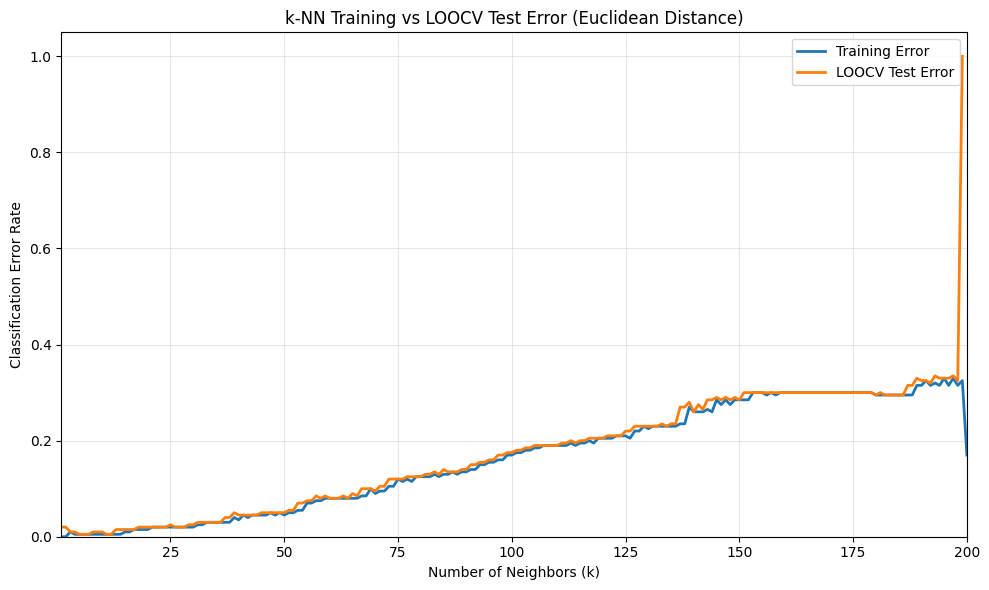

In [8]:

plt.figure(figsize=(10, 6))

plt.plot(
    errors_df["k"],
    errors_df["Training Error"],
    label="Training Error",
    linewidth=2
)

plt.plot(
    errors_df["k"],
    errors_df["LOOCV Test Error"],
    label="LOOCV Test Error",
    linewidth=2
)

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Classification Error Rate")
plt.title("k-NN Training vs LOOCV Test Error (Euclidean Distance)")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(1, 200)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


### Complete Jupyter Notebook code for Q7

### Create and visualize the exact dataset

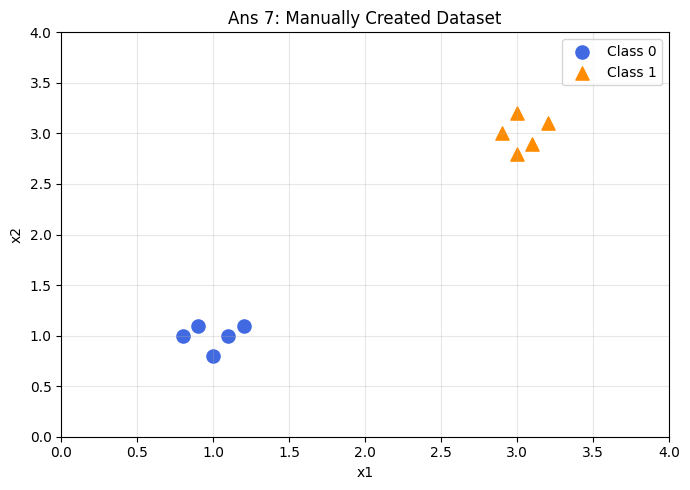

In [9]:

# CS6220 HW3 - Answer 7
# Dataset and initial scatterplot

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

data_q7 = np.array([
    [0.9, 1.1, 0],
    [1.0, 0.8, 0],
    [1.1, 1.0, 0],
    [0.8, 1.0, 0],
    [1.2, 1.1, 0],
    [3.1, 2.9, 1],
    [3.0, 3.2, 1],
    [2.9, 3.0, 1],
    [3.2, 3.1, 1],
    [3.0, 2.8, 1]
])

X_q7 = data_q7[:, :2]
y_q7 = data_q7[:, 2].astype(int)

assert X_q7.shape == (10, 2)
assert np.array_equal(np.bincount(y_q7), [5, 5])

plt.figure(figsize=(7, 5))

plt.scatter(
    X_q7[y_q7 == 0, 0],
    X_q7[y_q7 == 0, 1],
    color="royalblue",
    marker="o",
    s=90,
    label="Class 0"
)

plt.scatter(
    X_q7[y_q7 == 1, 0],
    X_q7[y_q7 == 1, 1],
    color="darkorange",
    marker="^",
    s=90,
    label="Class 1"
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Ans 7: Manually Created Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.tight_layout()
plt.show()


### Perceptron and training-error functions

In [10]:

# Perceptron training rule from Answer 6

def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y = training_record

    z = w1 * x1 + w2 * x2 + b
    predicted_y = 1 if z >= 0 else 0

    error = y - predicted_y

    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error

    return w1, w2, b


def perceptron_predictions(X, w1, w2, b):
    z = w1 * X[:, 0] + w2 * X[:, 1] + b
    return (z >= 0).astype(int)


def training_error_q7(X, y, w1, w2, b):
    predictions = perceptron_predictions(X, w1, w2, b)
    mistakes = np.sum(predictions != y)

    return int(mistakes), float(mistakes / len(y))


### Decision-boundary visualization

In [11]:

def plot_perceptron_q7(X, y, w1, w2, b, title):
    fig, ax = plt.subplots(figsize=(7, 5))

    for label, color, marker in [
        (0, "royalblue", "o"),
        (1, "darkorange", "^")
    ]:
        mask = y == label
        ax.scatter(
            X[mask, 0],
            X[mask, 1],
            c=color,
            marker=marker,
            s=90,
            edgecolors="black",
            label=f"Class {label}",
            zorder=3
        )

    x_values = np.linspace(0, 4, 400)

    if abs(w2) > 1e-12:
        y_values = -(w1 * x_values + b) / w2
        ax.plot(
            x_values, y_values,
            color="black",
            linewidth=2,
            label="Decision boundary"
        )
    elif abs(w1) > 1e-12:
        ax.axvline(
            -b / w1,
            color="black",
            linewidth=2,
            label="Decision boundary"
        )
    else:
        ax.text(
            0.5, 0.95,
            "No finite decision boundary",
            transform=ax.transAxes,
            ha="center"
        )

    mistakes, error_rate = training_error_q7(
        X, y, w1, w2, b
    )

    ax.set_title(
        f"{title}\n"
        f"Training Error: {mistakes}/10 ({error_rate:.0%})"
    )
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 4)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()


### Start with maximum error and train one record at a time

Initial mistakes: 10
Initial training error: 100%


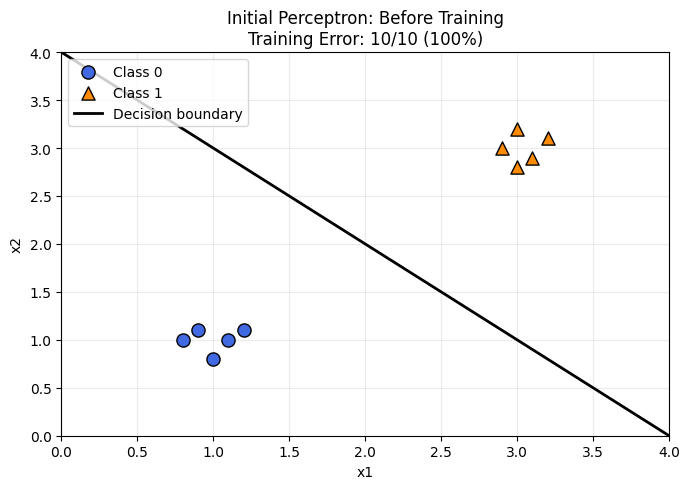

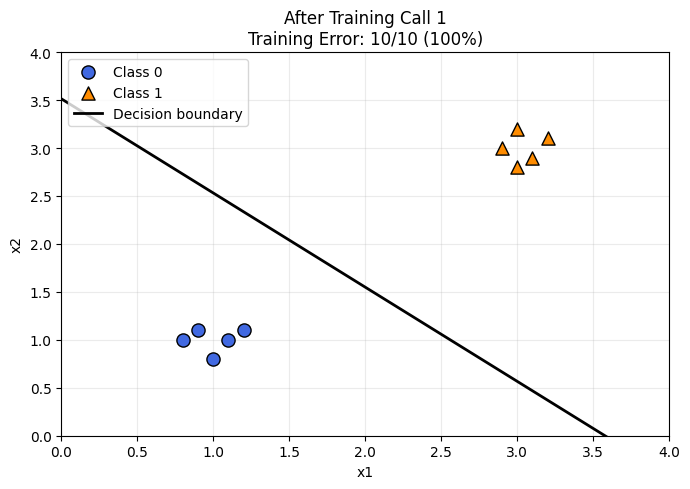

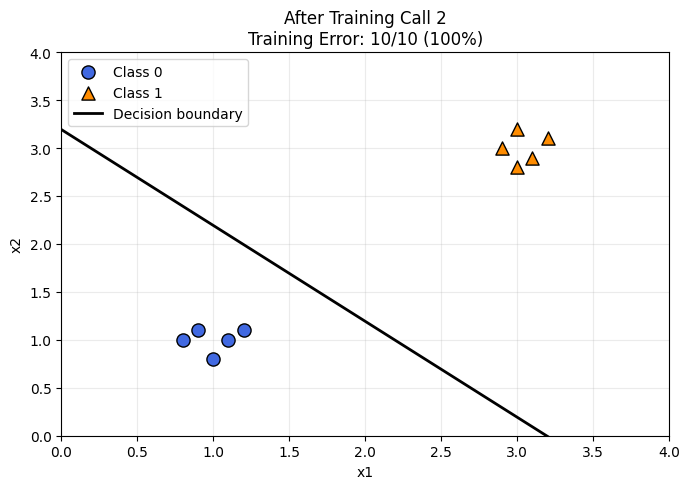

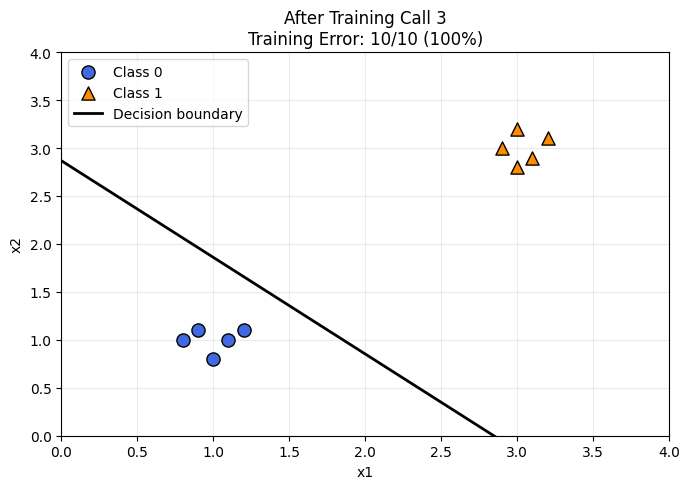

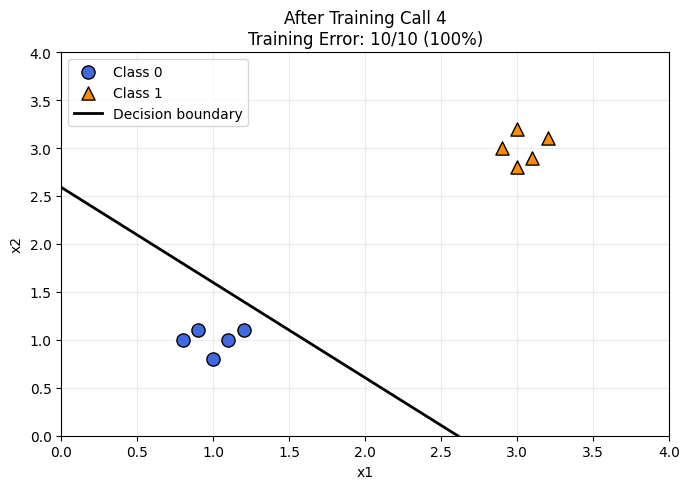

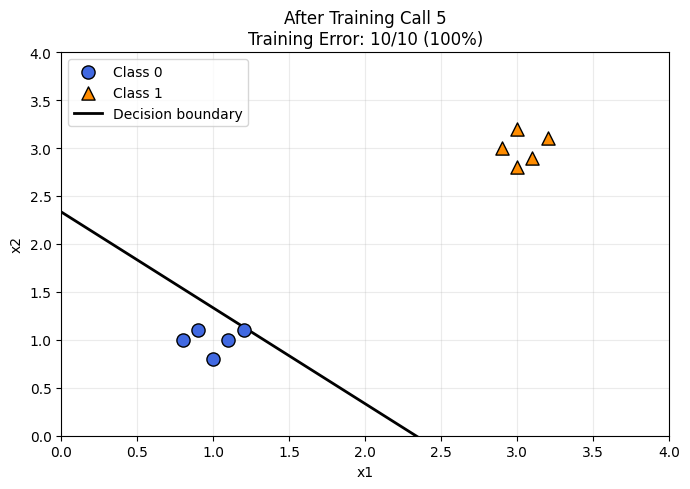

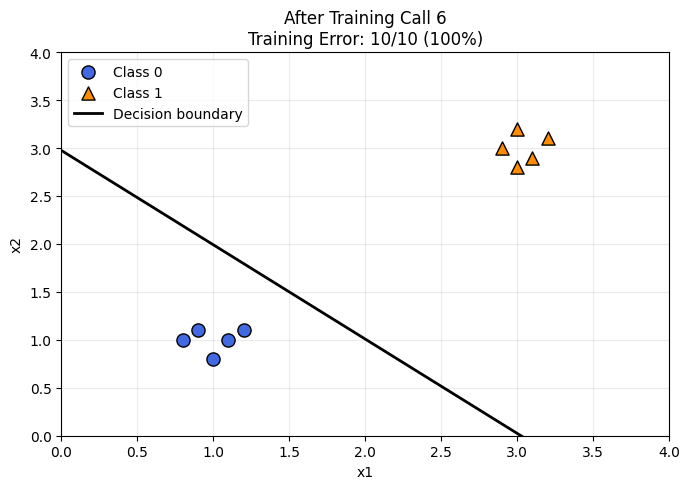

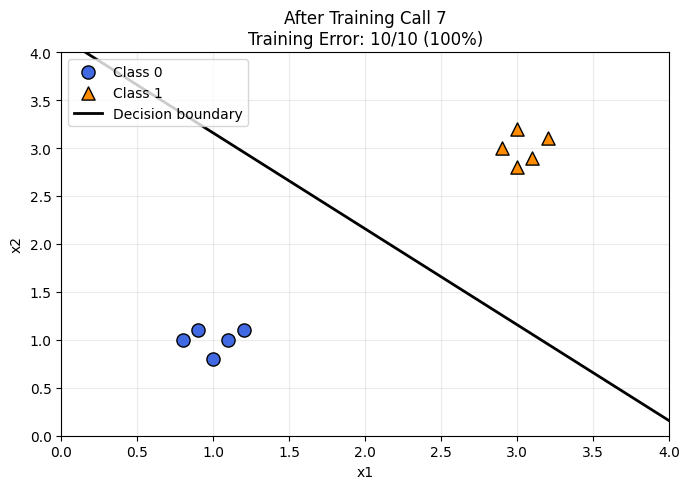

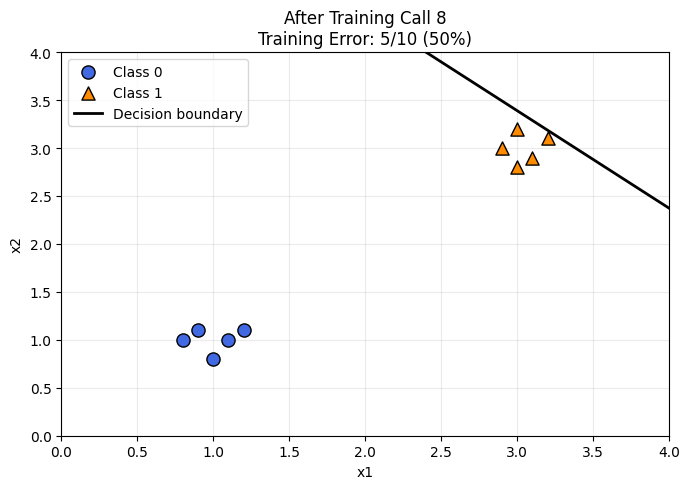

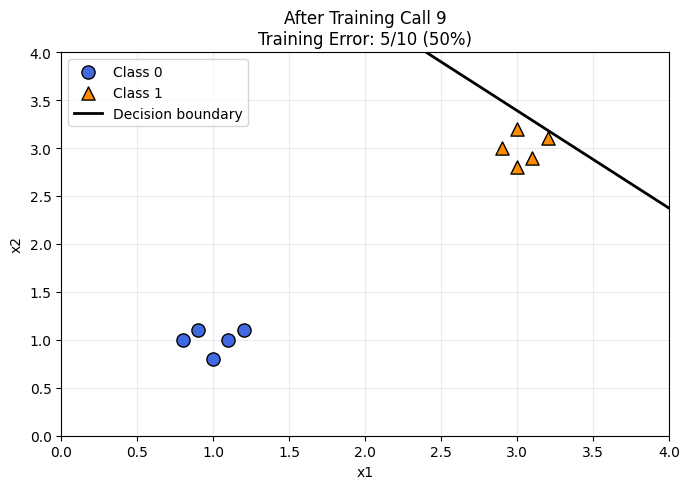

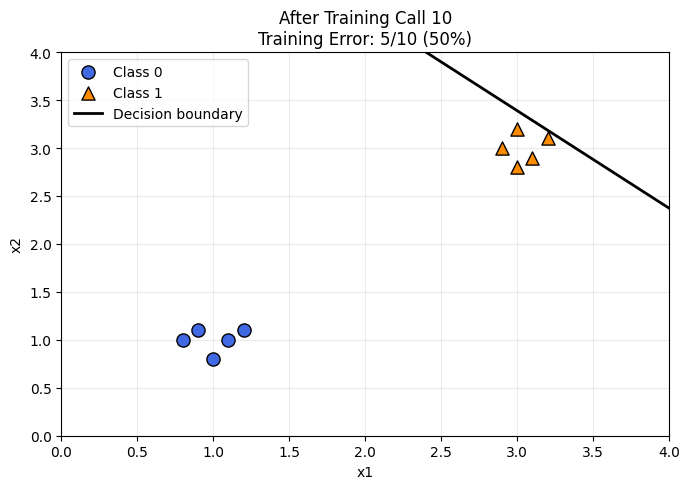


Training history:
 Call  Epoch  Record    w1    w2             b  Mistakes  Training Error
    1      1       1 -1.09 -1.11  3.900000e+00        10             1.0
    2      1       2 -1.19 -1.19  3.800000e+00        10             1.0
    3      1       3 -1.30 -1.29  3.700000e+00        10             1.0
    4      1       4 -1.38 -1.39  3.600000e+00        10             1.0
    5      1       5 -1.50 -1.50  3.500000e+00        10             1.0
    6      1       6 -1.19 -1.21  3.600000e+00        10             1.0
    7      1       7 -0.89 -0.89  3.700000e+00        10             1.0
    8      1       8 -0.60 -0.59  3.800000e+00         5             0.5
    9      1       9 -0.60 -0.59  3.800000e+00         5             0.5
   10      1      10 -0.60 -0.59  3.800000e+00         5             0.5
   11      2       1 -0.69 -0.70  3.700000e+00        10             1.0
   12      2       2 -0.79 -0.78  3.600000e+00        10             1.0
   13      2       3 -0.90 -0.88

In [12]:

# Initial parameters deliberately chosen for maximum error

w1, w2, b = -1.0, -1.0, 4.0
learning_rate = 0.1

initial_mistakes, initial_error = training_error_q7(
    X_q7, y_q7, w1, w2, b
)

print("Initial mistakes:", initial_mistakes)
print("Initial training error:", f"{initial_error:.0%}")

assert initial_mistakes == 10

plot_perceptron_q7(
    X_q7, y_q7, w1, w2, b,
    "Initial Perceptron: Before Training"
)

history_q7 = []
best_error = initial_error
best_parameters = (w1, w2, b)
best_call = 0

max_epochs = 100
call_number = 0

for epoch in range(1, max_epochs + 1):

    for record_index, record in enumerate(data_q7, start=1):
        call_number += 1

        # Use parameters updated by the previous call
        w1, w2, b = train_perceptron(
            record,
            learning_rate,
            w1, w2, b
        )

        mistakes, error_rate = training_error_q7(
            X_q7, y_q7, w1, w2, b
        )

        history_q7.append({
            "Call": call_number,
            "Epoch": epoch,
            "Record": record_index,
            "w1": w1,
            "w2": w2,
            "b": b,
            "Mistakes": mistakes,
            "Training Error": error_rate
        })

        if error_rate < best_error:
            best_error = error_rate
            best_parameters = (w1, w2, b)
            best_call = call_number

        # Show consecutive calls at the beginning
        if call_number <= 10:
            plot_perceptron_q7(
                X_q7, y_q7, w1, w2, b,
                f"After Training Call {call_number}"
            )

    # Stop once perfect separation is achieved
    if best_error == 0:
        break

history_df_q7 = pd.DataFrame(history_q7)

print("\nTraining history:")
print(history_df_q7.to_string(index=False))

print("\nBest training error:", f"{best_error:.0%}")
print("Best model found after call:", best_call)
print("Best parameters:", best_parameters)


### Plot the model with minimum training error

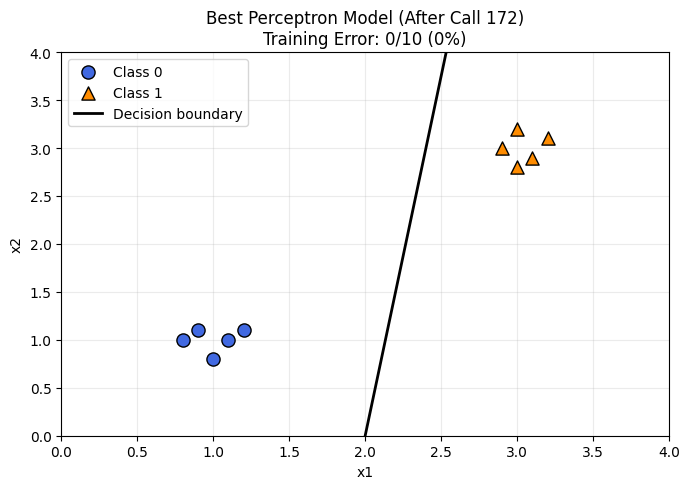

Best model training error: 0%
Number of misclassified records: 0
YES: The model perfectly separates both classes.


In [13]:

best_w1, best_w2, best_b = best_parameters

plot_perceptron_q7(
    X_q7,
    y_q7,
    best_w1,
    best_w2,
    best_b,
    f"Best Perceptron Model (After Call {best_call})"
)

best_mistakes, best_error_check = training_error_q7(
    X_q7, y_q7,
    best_w1, best_w2, best_b
)

print("Best model training error:", f"{best_error_check:.0%}")
print("Number of misclassified records:", best_mistakes)

if best_mistakes == 0:
    print("YES: The model perfectly separates both classes.")
else:
    print("NO: Perfect separation was not achieved.")


### Plot error after every training call

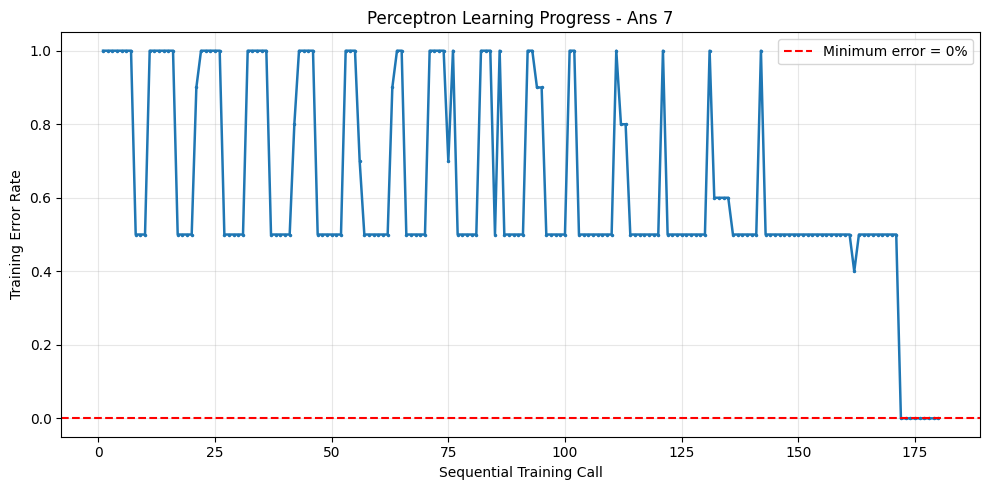

In [14]:

plt.figure(figsize=(10, 5))

plt.plot(
    history_df_q7["Call"],
    history_df_q7["Training Error"],
    linewidth=1.8,
    marker=".",
    markersize=3
)

plt.axhline(
    best_error,
    color="red",
    linestyle="--",
    label=f"Minimum error = {best_error:.0%}"
)

plt.xlabel("Sequential Training Call")
plt.ylabel("Training Error Rate")
plt.title("Perceptron Learning Progress - Ans 7")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Include a compact training-error table.

In [15]:
display(
    history_df_q7[
        ["Call", "Record", "w1", "w2", "b",
         "Mistakes", "Training Error"]
    ].head(10)
)

,Call,Record,w1,w2,b,Mistakes,Training Error
0,1,1,-1.09,-1.11,3.9,10,1.0
1,2,2,-1.19,-1.19,3.8,10,1.0
2,3,3,-1.30,-1.29,3.7,10,1.0
3,4,4,-1.38,-1.39,3.6,10,1.0
4,5,5,-1.50,-1.50,3.5,10,1.0
5,6,6,-1.19,-1.21,3.6,10,1.0
6,7,7,-0.89,-0.89,3.7,10,1.0
7,8,8,-0.60,-0.59,3.8,5,0.5
8,9,9,-0.60,-0.59,3.8,5,0.5
9,10,10,-0.60,-0.59,3.8,5,0.5


### Complete Python code for Answer 8

### Step 1: Create augmented dataset

In [16]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Original Q7 dataset
data_q7 = np.array([
    [0.9, 1.1, 0],
    [1.0, 0.8, 0],
    [1.1, 1.0, 0],
    [0.8, 1.0, 0],
    [1.2, 1.1, 0],
    [3.1, 2.9, 1],
    [3.0, 3.2, 1],
    [2.9, 3.0, 1],
    [3.2, 3.1, 1],
    [3.0, 2.8, 1]
])

# Add the new Q8 record
new_record = np.array([[1.0, 1.0, 1]])
data_q8 = np.vstack([data_q7, new_record])

X_q8 = data_q8[:, :2]
y_q8 = data_q8[:, 2].astype(int)

print("Number of records:", len(data_q8))
print("Class 0 records:", np.sum(y_q8 == 0))
print("Class 1 records:", np.sum(y_q8 == 1))

assert len(data_q8) == 11
assert np.sum(y_q8 == 0) == 5
assert np.sum(y_q8 == 1) == 6


Number of records: 11
Class 0 records: 5
Class 1 records: 6


### Step 2: Plot augmented dataset

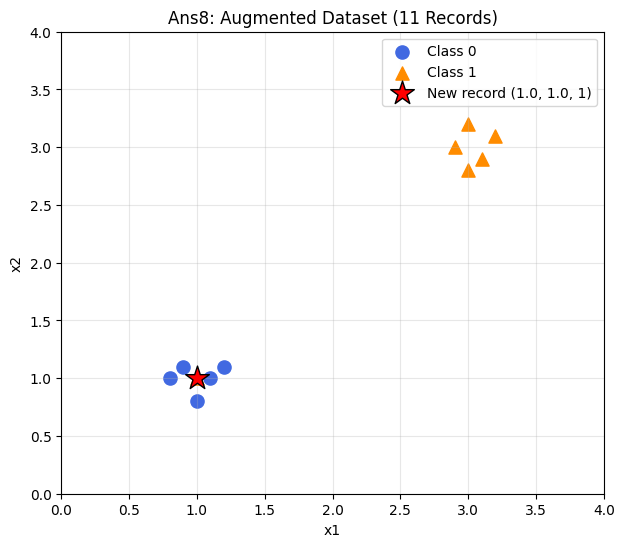

In [17]:

plt.figure(figsize=(7, 6))

plt.scatter(
    X_q8[y_q8 == 0, 0],
    X_q8[y_q8 == 0, 1],
    color="royalblue", marker="o",
    s=90, label="Class 0"
)

plt.scatter(
    X_q8[y_q8 == 1, 0],
    X_q8[y_q8 == 1, 1],
    color="darkorange", marker="^",
    s=90, label="Class 1"
)

plt.scatter(
    1.0, 1.0, marker="*",
    s=320, color="red",
    edgecolor="black",
    label="New record (1.0, 1.0, 1)",
    zorder=5
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Ans8: Augmented Dataset (11 Records)")
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Step 3: Re-run sequential perceptron training

In [18]:

learning_rate_q8 = 0.1

# Same initial parameters used in Q7
w1, w2, b = -1.0, -1.0, 4.0

epochs_q8 = 18
history_q8 = []

best_error_q8 = float("inf")
best_parameters_q8 = None
best_call_q8 = None

# Training error on the entire dataset
def evaluate_q8(w1, w2, b):
    z = X_q8[:, 0]*w1 + X_q8[:, 1]*w2 + b
    predictions = (z >= 0).astype(int)
    mistakes = int(np.sum(predictions != y_q8))
    return mistakes, mistakes / len(y_q8)

call_number = 0

for epoch in range(1, epochs_q8 + 1):
    for record_index, record in enumerate(data_q8, start=1):

        call_number += 1

        # Reuse the Q7 perceptron function
        w1, w2, b = train_perceptron(
            tuple(record),
            learning_rate_q8,
            w1, w2, b
        )

        mistakes, error = evaluate_q8(w1, w2, b)

        history_q8.append({
            "Call": call_number,
            "Epoch": epoch,
            "Record": record_index,
            "w1": w1,
            "w2": w2,
            "b": b,
            "Mistakes": mistakes,
            "Training Error": error
        })

        if error < best_error_q8:
            best_error_q8 = error
            best_parameters_q8 = (w1, w2, b)
            best_call_q8 = call_number

history_df_q8 = pd.DataFrame(history_q8)

print("Total training calls:", call_number)
print("Best training error:", f"{best_error_q8:.2%}")
print("Best model found at call:", best_call_q8)
print("Best parameters:", best_parameters_q8)

display(history_df_q8.head(11))
display(history_df_q8.tail(11))


Total training calls: 198
Best training error: 9.09%
Best model found at call: 189
Best parameters: (np.float64(0.15000000000000066), np.float64(-0.020000000000000434), np.float64(-0.30000000000000243))


,Call,Epoch,Record,w1,w2,b,Mistakes,Training Error
0,1,1,1,-1.09,-1.11,3.9,10,0.909091
1,2,1,2,-1.19,-1.19,3.8,10,0.909091
2,3,1,3,-1.30,-1.29,3.7,10,0.909091
3,4,1,4,-1.38,-1.39,3.6,10,0.909091
4,5,1,5,-1.50,-1.50,3.5,10,0.909091
5,6,1,6,-1.19,-1.21,3.6,10,0.909091
6,7,1,7,-0.89,-0.89,3.7,10,0.909091
7,8,1,8,-0.60,-0.59,3.8,5,0.454545
8,9,1,9,-0.60,-0.59,3.8,5,0.454545
9,10,1,10,-0.60,-0.59,3.8,5,0.454545


,Call,Epoch,Record,w1,w2,b,Mistakes,Training Error
187,188,18,1,0.25,0.06,-0.2,5,0.454545
188,189,18,2,0.15,-0.02,-0.3,1,0.090909
189,190,18,3,0.15,-0.02,-0.3,1,0.090909
190,191,18,4,0.15,-0.02,-0.3,1,0.090909
191,192,18,5,0.15,-0.02,-0.3,1,0.090909
192,193,18,6,0.15,-0.02,-0.3,1,0.090909
193,194,18,7,0.15,-0.02,-0.3,1,0.090909
194,195,18,8,0.15,-0.02,-0.3,1,0.090909
195,196,18,9,0.15,-0.02,-0.3,1,0.090909
196,197,18,10,0.15,-0.02,-0.3,1,0.090909


### Step 4: Plot training error versus training calls

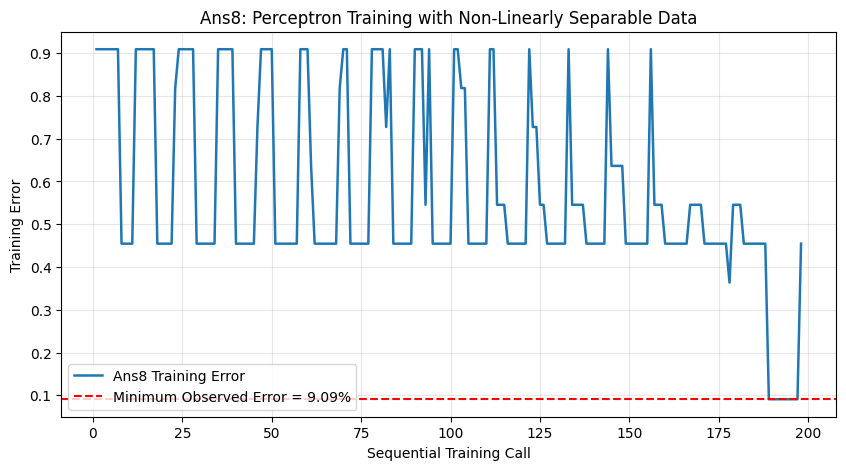

In [19]:

plt.figure(figsize=(10, 5))

plt.plot(
    history_df_q8["Call"],
    history_df_q8["Training Error"],
    linewidth=1.8,
    label="Ans8 Training Error"
)

plt.axhline(
    best_error_q8,
    color="red",
    linestyle="--",
    label=f"Minimum Observed Error = {best_error_q8:.2%}"
)

plt.xlabel("Sequential Training Call")
plt.ylabel("Training Error")
plt.title("Ans8: Perceptron Training with Non-Linearly Separable Data")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Step 5: Plot the best decision boundary

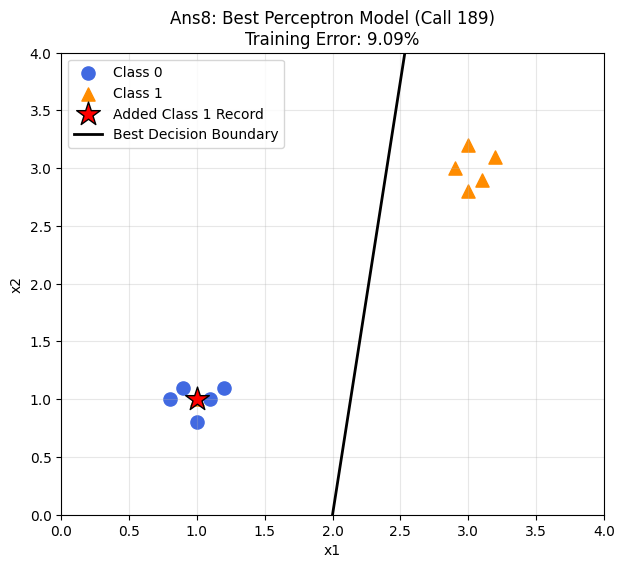

In [21]:

best_w1, best_w2, best_b = best_parameters_q8

plt.figure(figsize=(7, 6))

plt.scatter(
    X_q8[y_q8 == 0, 0],
    X_q8[y_q8 == 0, 1],
    color="royalblue", marker="o",
    s=90, label="Class 0"
)

plt.scatter(
    X_q8[y_q8 == 1, 0],
    X_q8[y_q8 == 1, 1],
    color="darkorange", marker="^",
    s=90, label="Class 1"
)

plt.scatter(
    1.0, 1.0,
    marker="*", s=320,
    color="red", edgecolor="black",
    label="Added Class 1 Record",
    zorder=5
)

x_values = np.linspace(0, 4, 300)

if abs(best_w2) > 1e-12:
    y_values = -(best_w1*x_values + best_b)/best_w2
    plt.plot(x_values, y_values, "k-", linewidth=2,
             label="Best Decision Boundary")
elif abs(best_w1) > 1e-12:
    plt.axvline(-best_b/best_w1, color="black",
                linewidth=2, label="Best Decision Boundary")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title(
    f"Ans8: Best Perceptron Model (Call {best_call_q8})\n"
    f"Training Error: {best_error_q8:.2%}"
)
plt.xlim(0, 4)
plt.ylim(0, 4)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Ans9 — Step 1: Generate the dataset

Dataset shape: (100, 2)
Number of records: 100
Feature range: (np.float64(0.007362269751005512), np.float64(0.9756223516367559))
Maximum absolute noise: 0.09847511281116716

First 5 records:


,x,y
0,0.773956,4.629628
1,0.438878,3.917698
2,0.858598,4.670370
3,0.697368,4.488571
4,0.094177,3.244105


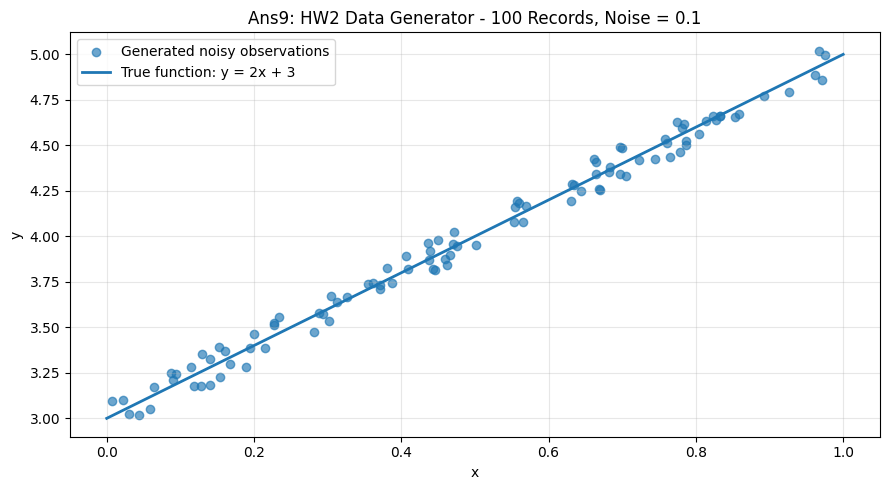

In [22]:

# Ans9 - Step 1: Generate dataset using HW2 data generator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the exact data generator from Homework 2
def generate_noisy_dataset(feature_functions, true_function,
                           x_range, n_samples, epsilon, seed=42):

    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], n_samples)

    features = [x]
    for function in feature_functions:
        features.append(function(x))

    noise = rng.uniform(-epsilon, epsilon, n_samples)

    y = true_function(x) + noise

    dataset = np.column_stack(features + [y])

    return dataset


# True function specified in Q9
def true_function_q9(x):
    return 2 * x + 3


# Generate exactly 100 records
data_q9 = generate_noisy_dataset(
    feature_functions=[],
    true_function=true_function_q9,
    x_range=(0, 1),
    n_samples=100,
    epsilon=0.1,
    seed=42
)

# Separate input and target
X_q9 = data_q9[:, 0]
y_q9 = data_q9[:, 1]

# Verify all required conditions
assert data_q9.shape == (100, 2)
assert np.all((X_q9 >= 0) & (X_q9 <= 1))
assert np.all(
    np.abs(y_q9 - true_function_q9(X_q9)) <= 0.1 + 1e-12
)

print("Dataset shape:", data_q9.shape)
print("Number of records:", len(data_q9))
print("Feature range:", (X_q9.min(), X_q9.max()))
print("Maximum absolute noise:",
      np.max(np.abs(y_q9 - true_function_q9(X_q9))))

print("\nFirst 5 records:")
display(pd.DataFrame(
    data_q9,
    columns=["x", "y"]
).head())

# Plot generated observations and true function
x_plot = np.linspace(0, 1, 500)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_q9, y_q9,
    alpha=0.65,
    label="Generated noisy observations"
)

plt.plot(
    x_plot,
    true_function_q9(x_plot),
    linewidth=2,
    label="True function: y = 2x + 3"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Ans9: HW2 Data Generator - 100 Records, Noise = 0.1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 2: Implement neuron training with parameter history

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Activation functions and derivatives

def activation_q9(z, name):
    if name == "relu":
        return np.maximum(0, z)
    elif name == "sigmoid":
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
    elif name == "tanh":
        return np.tanh(z)
    elif name == "linear":
        return z
    else:
        raise ValueError("Unknown activation function")


def activation_derivative_q9(z, name):
    if name == "relu":
        return (z > 0).astype(float)
    elif name == "sigmoid":
        a = activation_q9(z, "sigmoid")
        return a * (1 - a)
    elif name == "tanh":
        a = np.tanh(z)
        return 1 - a**2
    elif name == "linear":
        return np.ones_like(z)
    else:
        raise ValueError("Unknown activation function")


# Squared-error cost:
# C = (a - y)^2
# dC/da = 2(a - y)

def train_neuron_q9(
    X, y,
    activation_name="relu",
    learning_rate=0.01,
    epochs=100,
    w_initial=0.5,
    b_initial=0.5
):
    w = float(w_initial)
    b = float(b_initial)

    history = []

    # Record initial model
    initial_predictions = activation_q9(w * X + b, activation_name)

    history.append({
        "iteration": 0,
        "w": w,
        "b": b,
        "loss": np.mean((initial_predictions - y)**2)
    })

    # One training iteration = one record update
    for epoch in range(epochs):
        for x_i, y_i in zip(X, y):

            z = np.array([w * x_i + b])
            a = activation_q9(z, activation_name)[0]

            dC_da = 2 * (a - y_i)
            da_dz = activation_derivative_q9(
                z, activation_name
            )[0]

            delta = dC_da * da_dz

            gradient_w = delta * x_i
            gradient_b = delta

            w = w - learning_rate * gradient_w
            b = b - learning_rate * gradient_b

            predictions = activation_q9(
                w * X + b, activation_name
            )

            history.append({
                "iteration": len(history),
                "w": w,
                "b": b,
                "loss": np.mean((predictions - y)**2)
            })

    return w, b, pd.DataFrame(history)


### Step 3: Train different activation functions

In [24]:

# 9(a): Train different activation functions

activation_names = ["relu", "sigmoid", "tanh"]

q9_models = {}
q9_results = []

for activation_name in activation_names:

    w, b, history = train_neuron_q9(
        X_q9,
        y_q9,
        activation_name=activation_name,
        learning_rate=0.01,
        epochs=100,
        w_initial=0.5,
        b_initial=0.5
    )

    predictions = activation_q9(
        w * X_q9 + b,
        activation_name
    )

    rmse = np.sqrt(np.mean((predictions - y_q9)**2))

    q9_models[activation_name] = {
        "w": w,
        "b": b,
        "history": history,
        "rmse": rmse
    }

    q9_results.append({
        "Activation": activation_name,
        "Cost": "Squared Error",
        "Final Weight": w,
        "Final Bias": b,
        "Final RMSE": rmse
    })

results_q9a = pd.DataFrame(q9_results)

display(results_q9a.round(6))


,Activation,Cost,Final Weight,Final Bias,Final RMSE
0,relu,Squared Error,1.968791,3.013844,0.057575
1,sigmoid,Squared Error,2.594194,5.358701,3.023675
2,tanh,Squared Error,1.702685,3.575697,3.022583


### Step 4: Create the required animation

In [25]:

def animate_neuron_q9(
    X, y, history,
    activation_name,
    max_frames=120
):
    x_grid = np.linspace(0, 1, 300)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.scatter(
        X, y,
        alpha=0.45,
        label="Training observations"
    )

    ax.plot(
        x_grid,
        2 * x_grid + 3,
        linewidth=2,
        label="True function: y = 2x + 3"
    )

    model_line, = ax.plot(
        [], [],
        linewidth=2,
        linestyle="--",
        label="Neuron prediction"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 5.8)

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)

    frame_indices = np.unique(
        np.linspace(
            0,
            len(history) - 1,
            min(max_frames, len(history)),
            dtype=int
        )
    )

    def update(frame):
        row = history.iloc[frame]

        predictions = activation_q9(
            row["w"] * x_grid + row["b"],
            activation_name
        )

        model_line.set_data(x_grid, predictions)

        ax.set_title(
            f"Q9(a): {activation_name.upper()} + Squared Error\n"
            f"Iteration: {int(row['iteration'])} | "
            f"MSE: {row['loss']:.5f}"
        )

        return (model_line,)

    animation = FuncAnimation(
        fig,
        update,
        frames=frame_indices,
        interval=80,
        blit=False,
        repeat=False
    )

    plt.close(fig)

    return animation


# Required embedded animation: ReLU + Squared Error
animation_relu = animate_neuron_q9(
    X_q9,
    y_q9,
    q9_models["relu"]["history"],
    "relu"
)

display(HTML(animation_relu.to_jshtml()))


### Step 5: Animate the remaining combinations

In [26]:

# Sigmoid + Squared Error

animation_sigmoid = animate_neuron_q9(
    X_q9,
    y_q9,
    q9_models["sigmoid"]["history"],
    "sigmoid"
)

display(HTML(animation_sigmoid.to_jshtml()))


In [27]:

# Tanh + Squared Error

animation_tanh = animate_neuron_q9(
    X_q9,
    y_q9,
    q9_models["tanh"]["history"],
    "tanh"
)

display(HTML(animation_tanh.to_jshtml()))


### Step 6: Compare final predictions visually

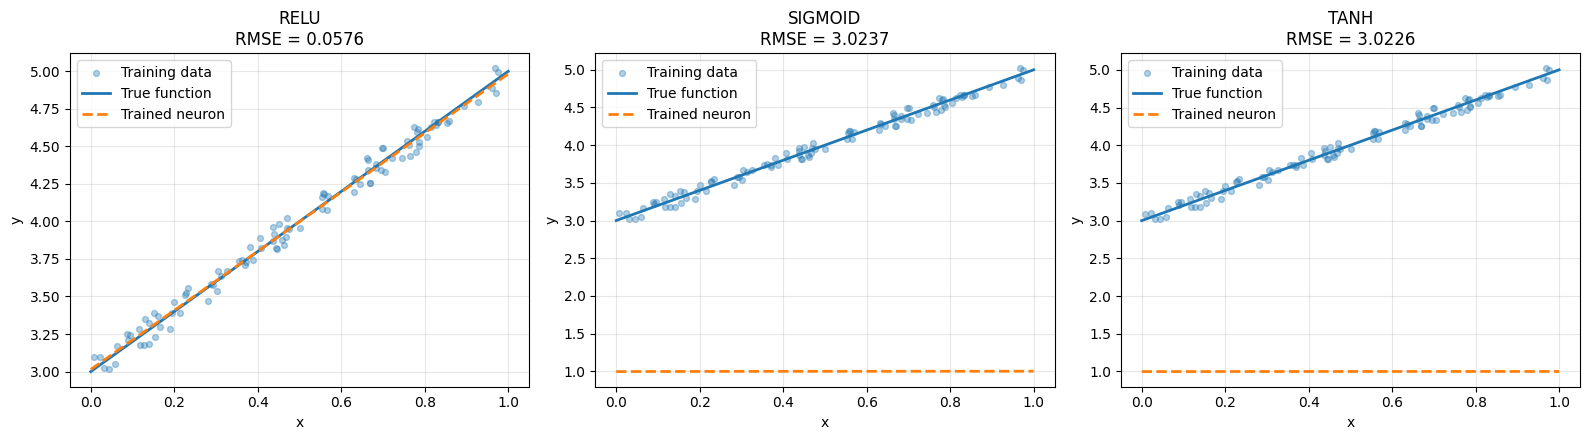

In [28]:

x_grid = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, activation_name in zip(axes, activation_names):

    model = q9_models[activation_name]

    predictions = activation_q9(
        model["w"] * x_grid + model["b"],
        activation_name
    )

    ax.scatter(
        X_q9, y_q9,
        alpha=0.35,
        s=18,
        label="Training data"
    )

    ax.plot(
        x_grid,
        true_function_q9(x_grid),
        linewidth=2,
        label="True function"
    )

    ax.plot(
        x_grid,
        predictions,
        linestyle="--",
        linewidth=2,
        label="Trained neuron"
    )

    ax.set_title(
        f"{activation_name.upper()}\n"
        f"RMSE = {model['rmse']:.4f}"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


### Ans 9(a): ReLU + Absolute Error (MAE)

### Step 1: Add the absolute-error derivative

In [29]:
import numpy as np

def absolute_error_derivative(y_true, y_pred):
    return np.sign(y_pred - y_true)

### Step 2: Update the neuron-training function

In [30]:

def train_neuron_q9(
    X, y,
    activation_name="relu",
    learning_rate=0.01,
    epochs=100,
    w_initial=0.5,
    b_initial=0.5,
    cost_name="squared_error"
):
    X = np.asarray(X, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    w = float(w_initial)
    b = float(b_initial)

    def calculate_loss(predictions):
        if cost_name == "squared_error":
            return np.mean((predictions - y) ** 2)
        elif cost_name == "absolute_error":
            return np.mean(np.abs(predictions - y))
        else:
            raise ValueError("Unsupported cost function")

    history = []

    initial_predictions = activation_q9(
        w * X + b, activation_name
    )

    history.append({
        "iteration": 0,
        "w": w,
        "b": b,
        "loss": calculate_loss(initial_predictions)
    })

    for epoch in range(epochs):
        for x_i, y_i in zip(X, y):

            z = np.array([w * x_i + b])
            a = activation_q9(z, activation_name)[0]

            if cost_name == "squared_error":
                dC_da = 2 * (a - y_i)
            else:
                dC_da = absolute_error_derivative(y_i, a)

            da_dz = activation_derivative_q9(
                z, activation_name
            )[0]

            delta = dC_da * da_dz

            gradient_w = delta * x_i
            gradient_b = delta

            w -= learning_rate * gradient_w
            b -= learning_rate * gradient_b

            predictions = activation_q9(
                w * X + b, activation_name
            )

            history.append({
                "iteration": len(history),
                "w": w,
                "b": b,
                "loss": calculate_loss(predictions)
            })

    return w, b, pd.DataFrame(history)


### Step 3: Train ReLU + Absolute Error

In [31]:

# 9(a): ReLU + Absolute Error (MAE)

w_mae, b_mae, history_mae = train_neuron_q9(
    X_q9,
    y_q9,
    activation_name="relu",
    learning_rate=0.01,
    epochs=100,
    w_initial=0.5,
    b_initial=0.5,
    cost_name="absolute_error"
)

predictions_mae = activation_q9(
    w_mae * X_q9 + b_mae,
    "relu"
)

mae = np.mean(np.abs(predictions_mae - y_q9))
rmse_mae = np.sqrt(
    np.mean((predictions_mae - y_q9) ** 2)
)

print("ReLU + Absolute Error Results")
print(f"Final weight: {w_mae:.6f}")
print(f"Final bias: {b_mae:.6f}")
print(f"Final MAE: {mae:.6f}")
print(f"Final RMSE: {rmse_mae:.6f}")

assert len(history_mae) == 10001
assert np.isfinite(history_mae[["w", "b", "loss"]].to_numpy()).all()


ReLU + Absolute Error Results
Final weight: 1.927859
Final bias: 3.020000
Final MAE: 0.051126
Final RMSE: 0.060693


### Step 4: Create the fourth interactive animation

In [32]:

def animate_neuron_q9(
    X, y, history,
    activation_name,
    max_frames=120,
    cost_name="squared_error"
):
    x_grid = np.linspace(0, 1, 300)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.scatter(
        X, y, alpha=0.45,
        label="Training observations"
    )

    ax.plot(
        x_grid, 2 * x_grid + 3,
        linewidth=2,
        label="True function: y = 2x + 3"
    )

    model_line, = ax.plot(
        [], [],
        linewidth=2,
        linestyle="--",
        label="Neuron prediction"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 5.8)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

    frame_indices = np.unique(
        np.linspace(
            0, len(history) - 1,
            min(max_frames, len(history)),
            dtype=int
        )
    )

    cost_label = (
        "Squared Error"
        if cost_name == "squared_error"
        else "Absolute Error"
    )

    metric_label = (
        "MSE"
        if cost_name == "squared_error"
        else "MAE"
    )

    def update(frame):
        row = history.iloc[frame]

        predictions = activation_q9(
            row["w"] * x_grid + row["b"],
            activation_name
        )

        model_line.set_data(x_grid, predictions)

        ax.set_title(
            f"Q9(a): {activation_name.upper()} + {cost_label}\n"
            f"Iteration: {int(row['iteration'])} | "
            f"{metric_label}: {row['loss']:.5f}"
        )

        return (model_line,)

    animation = FuncAnimation(
        fig,
        update,
        frames=frame_indices,
        interval=80,
        blit=False,
        repeat=False
    )

    plt.close(fig)
    return animation


animation_relu_mae = animate_neuron_q9(
    X_q9,
    y_q9,
    history_mae,
    "relu",
    cost_name="absolute_error"
)

display(HTML(animation_relu_mae.to_jshtml()))


### Step 5: Compare ReLU + Squared Error against ReLU + MAE

In [33]:

comparison_q9a = pd.DataFrame([
    {
        "Activation": "ReLU",
        "Cost": "Squared Error",
        "Weight": q9_models["relu"]["w"],
        "Bias": q9_models["relu"]["b"],
        "RMSE": q9_models["relu"]["rmse"]
    },
    {
        "Activation": "ReLU",
        "Cost": "Absolute Error",
        "Weight": w_mae,
        "Bias": b_mae,
        "RMSE": rmse_mae
    }
])

display(comparison_q9a.round(6))


,Activation,Cost,Weight,Bias,RMSE
0,ReLU,Squared Error,1.968791,3.013844,0.057575
1,ReLU,Absolute Error,1.927859,3.020000,0.060693


### Ans 9(c) — Effect of Learning Rate on Model Quality and Convergence

### Step 1: Run experiments with five learning rates

In [34]:

# 9(c): Compare different learning rates
# ReLU + Squared Error, using the same Q9 dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

learning_rates_q9c = [0.001, 0.01, 0.1, 1.0, 10.0]

results_q9c = []
histories_q9c = {}

for lr in learning_rates_q9c:

    # Reuse the existing train_neuron_q9 function
    # Suppress expected overflow warnings at extreme rates
    with np.errstate(over="ignore", invalid="ignore"):
        w, b, history = train_neuron_q9(
            X_q9,
            y_q9,
            activation_name="relu",
            learning_rate=lr,
            epochs=100,
            w_initial=0.5,
            b_initial=0.5,
            cost_name="squared_error"
        )

        predictions = activation_q9(
            w * np.asarray(X_q9).ravel() + b,
            "relu"
        )

        rmse = np.sqrt(
            np.mean((predictions - np.asarray(y_q9).ravel()) ** 2)
        )

    histories_q9c[lr] = history

    results_q9c.append({
        "Learning Rate": lr,
        "Final Weight": w,
        "Final Bias": b,
        "Final RMSE": rmse,
        "Finite Result": (
            np.isfinite(w)
            and np.isfinite(b)
            and np.isfinite(rmse)
        )
    })

results_df_q9c = pd.DataFrame(results_q9c)

display(results_df_q9c.round(6))


,Learning Rate,Final Weight,Final Bias,Final RMSE,Finite Result
0,0.001,1.932432,3.033909,0.058499,True
1,0.010,1.968791,3.013844,0.057575,True
2,0.100,1.954728,3.003681,0.060628,True
3,1.000,0.298571,-5.673886,4.010115,True
4,10.000,-793.695738,-1866.252224,4.010115,True


### Step 2: Plot convergence for all five learning rates

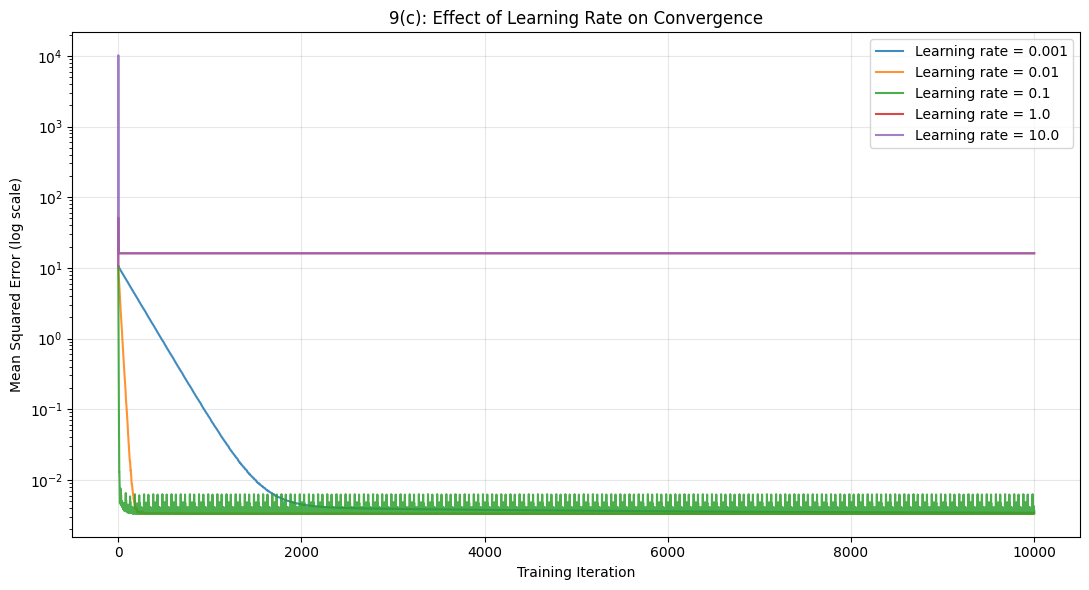

In [36]:

# 9(c): Convergence comparison

plt.figure(figsize=(11, 6))

for lr in learning_rates_q9c:

    history = histories_q9c[lr]

    iterations = history["iteration"].to_numpy()
    losses = history["loss"].to_numpy()

    # Show only valid, positive loss values
    valid = np.isfinite(losses) & (losses > 0)

    plt.plot(
        iterations[valid],
        losses[valid],
        label=f"Learning rate = {lr}",
        alpha=0.85
    )

plt.yscale("log")
plt.xlabel("Training Iteration")
plt.ylabel("Mean Squared Error (log scale)")
plt.title("9(c): Effect of Learning Rate on Convergence")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Step 3: Show two extreme examples

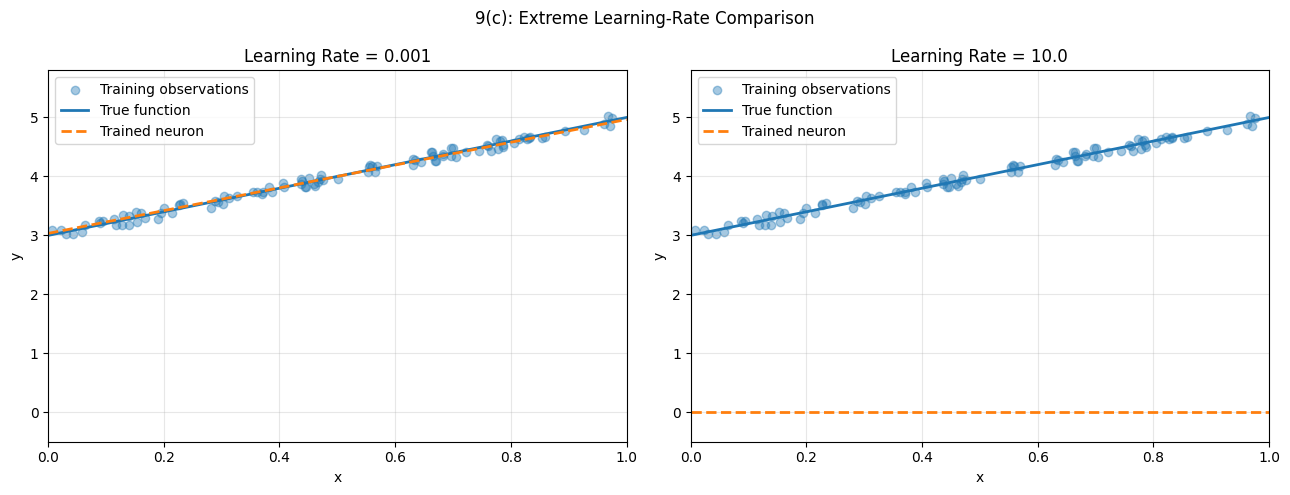

In [38]:

# 9(c): Extreme learning-rate examples

x_grid = np.linspace(0, 1, 300)
y_true = 2 * x_grid + 3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, lr in zip(axes, [0.001, 10.0]):

    row = results_df_q9c.loc[
        np.isclose(results_df_q9c["Learning Rate"], lr)
    ].iloc[0]

    w = row["Final Weight"]
    b = row["Final Bias"]

    ax.scatter(
        X_q9, y_q9,
        alpha=0.4,
        label="Training observations"
    )

    ax.plot(
        x_grid, y_true,
        linewidth=2,
        label="True function"
    )

    if np.isfinite(w) and np.isfinite(b):
        with np.errstate(over="ignore", invalid="ignore"):
            prediction = activation_q9(
                w * x_grid + b, "relu"
            )

        if np.all(np.isfinite(prediction)):
            ax.plot(
                x_grid, prediction,
                linestyle="--",
                linewidth=2,
                label="Trained neuron"
            )
        else:
            ax.text(
                0.5, 0.5,
                "Non-finite predictions",
                transform=ax.transAxes,
                ha="center"
            )
    else:
        ax.text(
            0.5, 0.5,
            "Training diverged numerically",
            transform=ax.transAxes,
            ha="center"
        )

    ax.set_title(f"Learning Rate = {lr}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 5.8)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("9(c): Extreme Learning-Rate Comparison")
plt.tight_layout()
plt.show()


### Ans 9(d): Weight and Bias Gradient Analysis

In [39]:

# 9(d): Track weight and bias gradients
# ReLU + Squared Error

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def train_neuron_q9d(
    X, y,
    learning_rate=0.01,
    epochs=100,
    w_initial=0.5,
    b_initial=0.5
):
    X = np.asarray(X, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    w = float(w_initial)
    b = float(b_initial)

    history = []

    for epoch in range(1, epochs + 1):
        for record, (x_i, y_i) in enumerate(zip(X, y), start=1):

            # Forward pass
            z = w * x_i + b
            a = max(0.0, z)

            # Squared-error derivative
            dC_da = 2.0 * (a - y_i)

            # ReLU derivative
            da_dz = 1.0 if z > 0 else 0.0

            # Chain rule
            delta = dC_da * da_dz

            gradient_w = delta * x_i
            gradient_b = delta

            # Store gradients BEFORE updating parameters
            history.append({
                "Iteration": len(history) + 1,
                "Epoch": epoch,
                "Record": record,
                "Gradient w": gradient_w,
                "Gradient b": gradient_b,
                "Weight Before": w,
                "Bias Before": b
            })

            # Gradient descent update
            w -= learning_rate * gradient_w
            b -= learning_rate * gradient_b

    return w, b, pd.DataFrame(history)


w_q9d, b_q9d, gradients_q9d = train_neuron_q9d(
    X_q9,
    y_q9,
    learning_rate=0.01,
    epochs=100,
    w_initial=0.5,
    b_initial=0.5
)

print("Q9(d): Gradient Tracking Results")
print(f"Final weight: {w_q9d:.6f}")
print(f"Final bias: {b_q9d:.6f}")
print(f"Total gradient records: {len(gradients_q9d)}")

display(gradients_q9d.head(10))

assert len(gradients_q9d) == 10000


Q9(d): Gradient Tracking Results
Final weight: 1.968791
Final bias: 3.013844
Total gradient records: 10000


,Iteration,Epoch,Record,Gradient w,Gradient b,Weight Before,Bias Before
0,1,1,1,-5.793294,-7.485300,0.500000,0.500000
1,2,1,2,-2.719274,-6.195961,0.557933,0.574853
2,3,1,3,-6.063710,-7.062339,0.585126,0.636813
3,4,1,4,-4.645588,-6.661602,0.645763,0.707436
4,5,1,5,-0.452967,-4.809723,0.692219,0.774052
5,6,1,6,-6.815132,-6.985420,0.696748,0.822149
6,7,1,7,-4.624613,-6.075906,0.764900,0.892003
7,8,1,8,-4.616087,-5.872403,0.811146,0.952763
8,9,1,9,-0.526339,-4.108372,0.857307,1.011487
9,10,1,10,-2.288170,-5.080465,0.862570,1.052570


### Verify consistency with  Q9(a) model

In [40]:

# Verify consistency with 9(a)

reference_w = q9_models["relu"]["w"]
reference_b = q9_models["relu"]["b"]

print("Original ReLU weight:", reference_w)
print("9(d) ReLU weight:", w_q9d)

print("Original ReLU bias:", reference_b)
print("9(d) ReLU bias:", b_q9d)

assert np.isclose(w_q9d, reference_w, atol=1e-8)
assert np.isclose(b_q9d, reference_b, atol=1e-8)

print("Verification passed: identical final parameters.")


Original ReLU weight: 1.9687907716302846
9(d) ReLU weight: 1.9687907716302846
Original ReLU bias: 3.0138441831924836
9(d) ReLU bias: 3.0138441831924836
Verification passed: identical final parameters.


### Plot both gradients across iterations

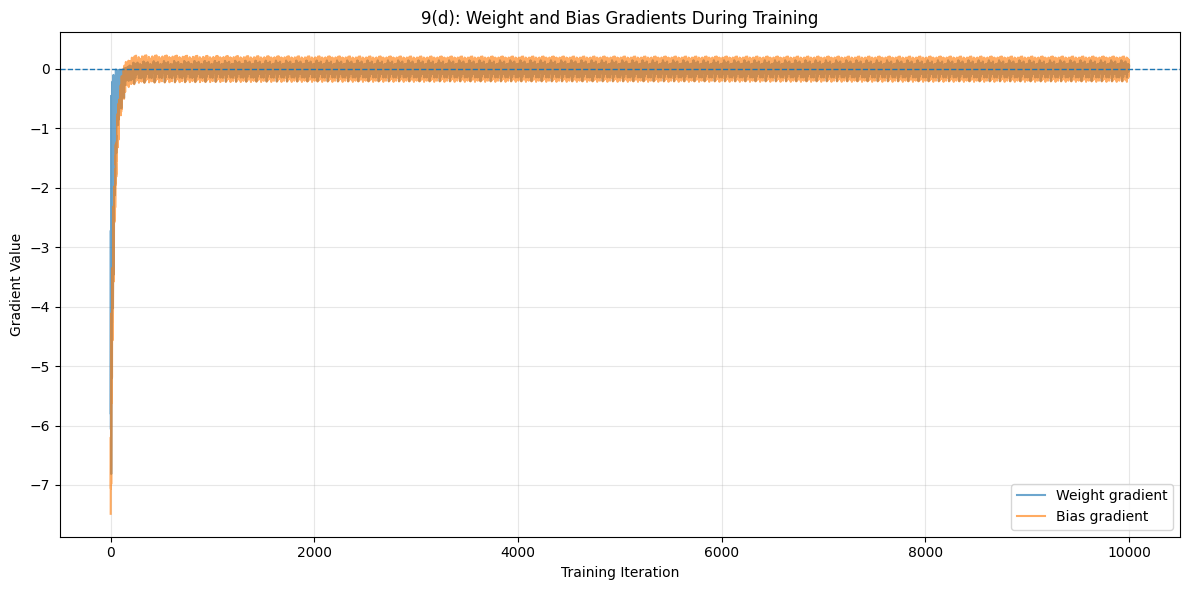

In [41]:

# 9(d): Weight and bias gradients versus iteration

plt.figure(figsize=(12, 6))

plt.plot(
    gradients_q9d["Iteration"],
    gradients_q9d["Gradient w"],
    label="Weight gradient",
    alpha=0.65
)

plt.plot(
    gradients_q9d["Iteration"],
    gradients_q9d["Gradient b"],
    label="Bias gradient",
    alpha=0.65
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Training Iteration")
plt.ylabel("Gradient Value")
plt.title("9(d): Weight and Bias Gradients During Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Plot the epoch-wise gradient trend

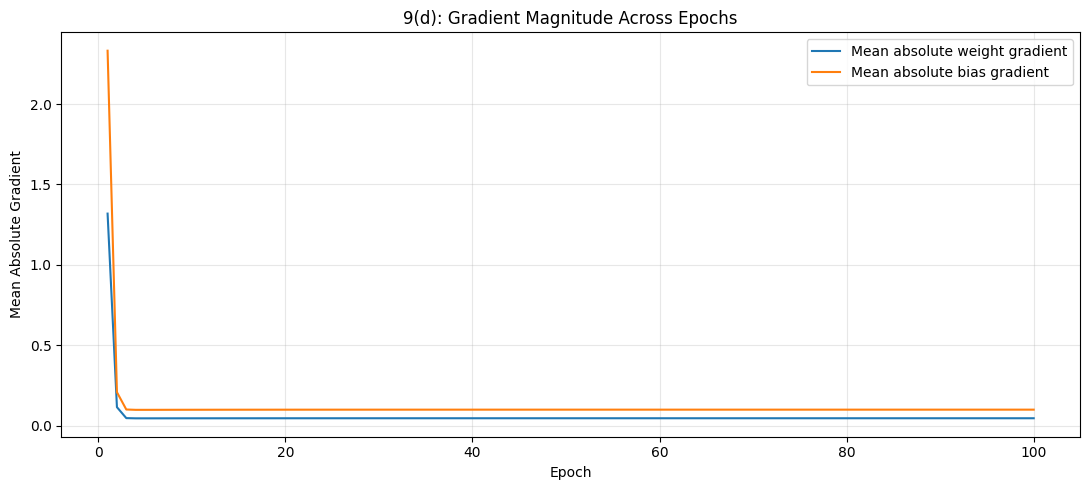

,Epoch,Abs_Gradient_w,Abs_Gradient_b
0,1,1.318988,2.331675
1,2,0.115613,0.208631
2,3,0.047487,0.101083
3,4,0.046148,0.098967
4,5,0.046110,0.098958
5,6,0.046151,0.099056
6,7,0.046209,0.099170
7,8,0.046263,0.099279
8,9,0.046312,0.099376
9,10,0.046355,0.099463


,Epoch,Abs_Gradient_w,Abs_Gradient_b
90,91,0.046694,0.100142
91,92,0.046694,0.100142
92,93,0.046694,0.100142
93,94,0.046694,0.100142
94,95,0.046694,0.100142
95,96,0.046694,0.100142
96,97,0.046694,0.100142
97,98,0.046694,0.100142
98,99,0.046694,0.100142
99,100,0.046694,0.100142


In [42]:

# 9(d): Mean absolute gradients by epoch

epoch_gradients_q9d = (
    gradients_q9d
    .assign(
        Abs_Gradient_w=lambda df: df["Gradient w"].abs(),
        Abs_Gradient_b=lambda df: df["Gradient b"].abs()
    )
    .groupby("Epoch")[
        ["Abs_Gradient_w", "Abs_Gradient_b"]
    ]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    epoch_gradients_q9d["Epoch"],
    epoch_gradients_q9d["Abs_Gradient_w"],
    label="Mean absolute weight gradient"
)

plt.plot(
    epoch_gradients_q9d["Epoch"],
    epoch_gradients_q9d["Abs_Gradient_b"],
    label="Mean absolute bias gradient"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Gradient")
plt.title("9(d): Gradient Magnitude Across Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(epoch_gradients_q9d.head(10))
display(epoch_gradients_q9d.tail(10))


### Ans 9(e): Linear Activation Function

Q9(e): Linear Activation Results
Final weight: 1.968791
Final bias: 3.013844
Final RMSE: 0.057575

Previous ReLU Results
Weight: 1.968791
Bias: 3.013844
RMSE: 0.057575


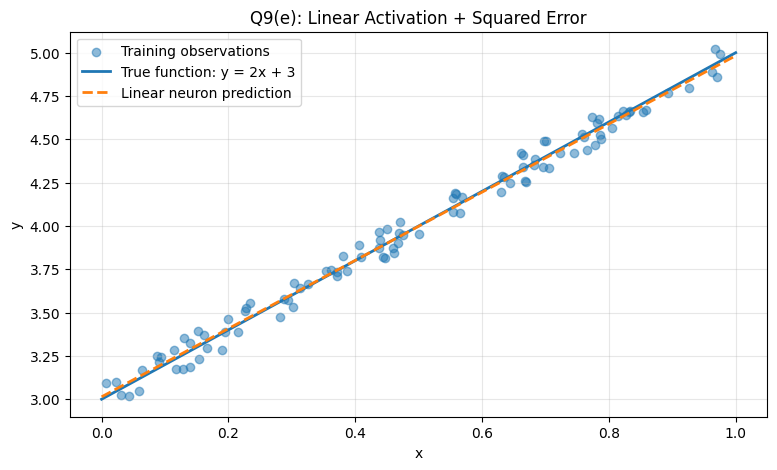

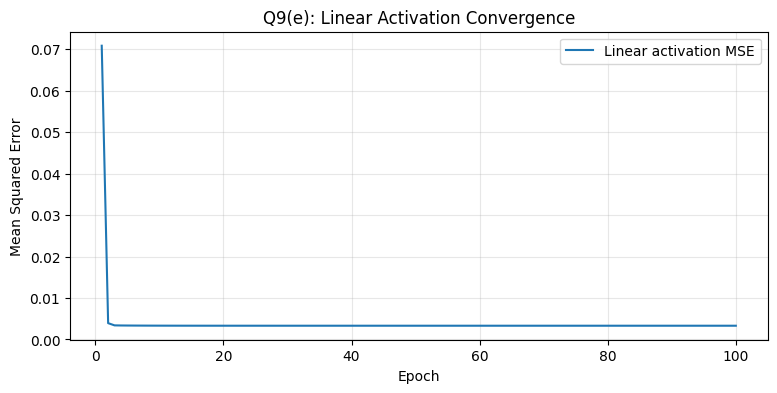

In [43]:

import numpy as np
import matplotlib.pyplot as plt

# Q9(e): Linear activation with squared-error cost

X_linear = np.asarray(X_q9).reshape(-1)
y_linear = np.asarray(y_q9).reshape(-1)

learning_rate = 0.01
epochs = 100

# Same initial parameters as Q9(a)
w = 0.5
b = 0.5

mse_history = []

# Sequential gradient descent
for epoch in range(epochs):
    for x, y in zip(X_linear, y_linear):

        z = w * x + b
        prediction = z  # Linear activation

        error = prediction - y

        gradient_w = 2 * error * x
        gradient_b = 2 * error

        w -= learning_rate * gradient_w
        b -= learning_rate * gradient_b

    predictions = w * X_linear + b
    mse_history.append(
        np.mean((predictions - y_linear) ** 2)
    )

linear_rmse = np.sqrt(mse_history[-1])

print("Q9(e): Linear Activation Results")
print(f"Final weight: {w:.6f}")
print(f"Final bias: {b:.6f}")
print(f"Final RMSE: {linear_rmse:.6f}")

print("\nPrevious ReLU Results")
print("Weight: 1.968791")
print("Bias: 3.013844")
print("RMSE: 0.057575")

# Plot true function and trained model
x_plot = np.linspace(0, 1, 200)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_linear, y_linear,
    alpha=0.5, label="Training observations"
)

plt.plot(
    x_plot, 2 * x_plot + 3,
    label="True function: y = 2x + 3",
    linewidth=2
)

plt.plot(
    x_plot, w * x_plot + b,
    "--", linewidth=2,
    label="Linear neuron prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Q9(e): Linear Activation + Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Convergence plot
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, epochs + 1),
    mse_history,
    label="Linear activation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Q9(e): Linear Activation Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [1]:

import json

filename = "homework_3_002535005.ipynb"

with open(filename, "r", encoding="utf-8") as f:
    nb = json.load(f)

sizes = []

for i, cell in enumerate(nb["cells"]):
    output_size = len(
        json.dumps(cell.get("outputs", []))
        .encode("utf-8")
    )

    sizes.append((i, output_size / (1024 ** 2)))

for i, size in sorted(sizes, key=lambda x: x[1], reverse=True)[:10]:
    print(f"Cell {i}: {size:.2f} MB")


Cell 52: 7.44 MB
Cell 64: 7.32 MB
Cell 50: 7.28 MB
Cell 53: 7.24 MB
Cell 25: 0.51 MB
Cell 9: 0.12 MB
Cell 83: 0.10 MB
Cell 55: 0.10 MB
Cell 40: 0.09 MB
Cell 71: 0.08 MB
